<div style="background:linear-gradient(135deg,#0a1230 0%,#141d44 55%,#1b1448 100%);border-radius:18px;padding:36px 32px;color:#fff;font-family:Inter,Segoe UI,sans-serif">
  <div style="font-size:12px;letter-spacing:3px;color:#00d4ff;font-weight:700;text-transform:uppercase">Part II · Describing Data &nbsp;|&nbsp; Chapter 10</div>
  <div style="font-size:40px;font-weight:900;line-height:1.1;margin:10px 0 6px">Measures of Position <span style="color:#00d4ff">🐍 Notebook</span></div>
  <div style="font-size:16px;color:#b9c2e0;max-width:720px;line-height:1.6">Five demos on where a single value sits in the crowd: percentiles and percentile rank, quartiles and deciles, the cumulative S-curve, why position is outlier-robust, and why software can disagree on the answer.</div>
  <div style="margin-top:18px;font-size:13px;color:#8892b0">Author: <b style="color:#e8eaf6">John Fisher</b> &nbsp;·&nbsp; Statistics, Data Science and AI: A Visual Handbook &nbsp;·&nbsp; 2026</div>
</div>

### 🎯 What you'll build in this notebook

| # | Demo | Idea it builds |
|---|------|----------------|
| 1 | The round trip | percentile (a value) vs percentile rank (a %) |
| 2 | Quartiles &amp; deciles | quantiles are one idea at different grain |
| 3 | The cumulative S-curve | read position two ways from one ogive |
| 4 | Position is robust | percentiles barely move when an outlier appears |
| 5 | Why answers differ | percentile calculation methods compared |

---

## ⚙️ Setup, imports & the book's plotting style

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(10)

NAVY="#0a1230"; INK="#1a2138"; INK_SOFT="#4a5578"
CYAN="#0891b2"; PURPLE="#7c3aed"; AMBER="#d97706"; GREEN="#059669"; PINK="#db2777"; BLUE="#2563eb"; GRID="#e6e9f2"
plt.rcParams.update({
    "figure.facecolor":"white","axes.facecolor":"white","figure.dpi":110,"font.size":11,
    "axes.edgecolor":GRID,"axes.linewidth":1.2,"axes.grid":True,"grid.color":GRID,"axes.axisbelow":True,
    "axes.spines.top":False,"axes.spines.right":False,"axes.titlesize":15,"axes.titleweight":"bold","axes.titlecolor":INK,
    "axes.labelcolor":INK_SOFT,"axes.labelsize":11.5,"xtick.color":INK_SOFT,"ytick.color":INK_SOFT,"legend.frameon":False,
})
def titlecard(ax,t,sub=None):
    ax.set_title(t, loc="left", pad=18)
    if sub: ax.text(0,1.02,sub,transform=ax.transAxes,fontsize=10.5,color=INK_SOFT,va="bottom")
print("✅ Environment ready.")

✅ Environment ready.


<div style="background:#e0f7fb;border-left:5px solid #0891b2;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#0e7490;letter-spacing:1px">DEMO 1 · THE ROUND TRIP</span>
<div style="font-size:22px;font-weight:800;color:#1a2138;margin-top:4px">🎯 Percentile vs percentile rank</div>
<div style="color:#4a5578;margin-top:6px">A percentile is a value at a position ("the score at the 75th percentile"). A percentile rank is a percentage ("this score beats 90% of people"). They are inverse operations.</div>
</div>

Percentile RANK of 82: 67%  (about 67% scored at or below 82)
The 75th PERCENTILE is a score of 85.8

Value -> rank, and rank -> value: the two directions undo each other.


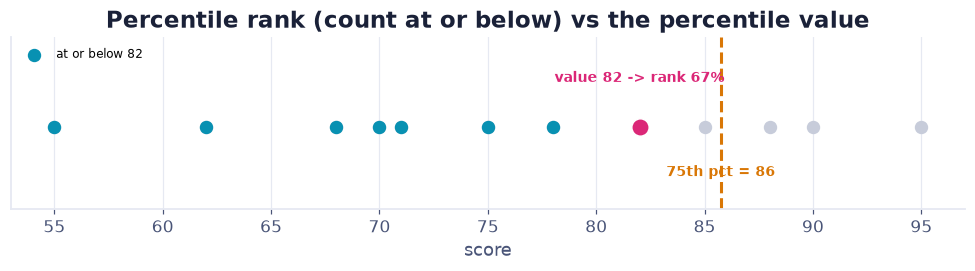

In [2]:
scores = pd.Series([55, 62, 68, 70, 71, 75, 78, 82, 85, 88, 90, 95])

# value -> rank: what percent scored at or below 82?
x = 82
rank = (scores <= x).mean() * 100
print(f"Percentile RANK of {x}: {rank:.0f}%  (about {rank:.0f}% scored at or below {x})")

# rank -> value: what score sits at the 75th percentile?
p75 = np.percentile(scores, 75)
print(f"The 75th PERCENTILE is a score of {p75:.1f}")
print("\nValue -> rank, and rank -> value: the two directions undo each other.")

# --- added visual ---
import matplotlib.pyplot as plt, numpy as np
_CY,_PU,_AM,_GR,_PK,_INK,_GRY,_BL = "#0891b2","#7c3aed","#d97706","#059669","#db2777","#1a2138","#c7ccda","#2563eb"
sv = np.sort(scores.values)
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.scatter(sv, np.zeros(len(sv)), s=60, color=_GRY, zorder=2)
le = sv[sv <= 82]
ax.scatter(le, np.zeros(len(le)), s=60, color=_CY, zorder=3, label="at or below 82")
ax.scatter([82],[0], s=130, color=_PK, zorder=4, edgecolor="white")
ax.text(82, 0.55, f"value 82 -> rank {rank:.0f}%", ha="center", color=_PK, fontweight="bold", fontsize=9)
ax.axvline(p75, color=_AM, lw=2, ls="--")
ax.text(p75, -0.6, f"75th pct = {p75:.0f}", ha="center", color=_AM, fontweight="bold", fontsize=9)
ax.set_ylim(-1, 1.1); ax.set_yticks([]); ax.set_xlabel("score"); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Percentile rank (count at or below) vs the percentile value")
plt.tight_layout(); plt.show()

<div style="background:#f0e9fe;border-left:5px solid #7c3aed;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#7c3aed;letter-spacing:1px">DEMO 2 · QUARTILES & DECILES</span>
<div style="font-size:22px;font-weight:800;color:#1a2138;margin-top:4px">📏 One idea at different resolutions</div>
<div style="color:#4a5578;margin-top:6px">Quartiles cut the data into 4 parts, deciles into 10, percentiles into 100. They are all quantiles. The median is the 50th percentile = 2nd quartile = 5th decile.</div>
</div>

Quartiles  Q1, Q2(median), Q3 : [69.5 76.5 85.8]
Deciles (10th..90th)          : [62.6 68.4 70.3 72.6 76.5 80.4 84.1 87.4 89.8]

The median 76.5 = 50th percentile = Q2 = 5th decile (all the same point).


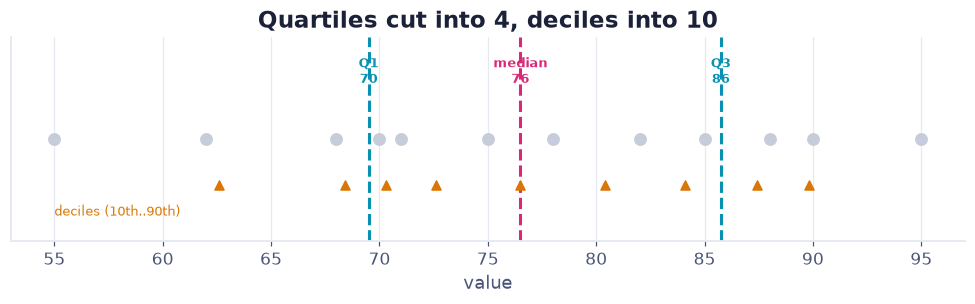

In [3]:
data = scores
q = np.percentile(data, [25, 50, 75])
print(f"Quartiles  Q1, Q2(median), Q3 : {q.round(1)}")

deciles = np.percentile(data, np.arange(10, 100, 10))
print(f"Deciles (10th..90th)          : {deciles.round(1)}")

print(f"\nThe median {np.percentile(data,50):.1f} = 50th percentile = Q2 = 5th decile (all the same point).")

# --- added visual ---
import matplotlib.pyplot as plt, numpy as np
_CY,_PU,_AM,_GR,_PK,_INK,_GRY,_BL = "#0891b2","#7c3aed","#d97706","#059669","#db2777","#1a2138","#c7ccda","#2563eb"
fig, ax = plt.subplots(figsize=(9, 2.9))
ax.scatter(data.values, np.zeros(len(data)), s=55, color=_GRY, zorder=2)
for val, lab, c in [(q[0],"Q1",_CY),(q[1],"median",_PK),(q[2],"Q3",_CY)]:
    ax.axvline(val, color=c, lw=2, ls="--")
    ax.text(val, 0.55, f"{lab}\n{val:.0f}", ha="center", color=c, fontweight="bold", fontsize=8.5)
ax.scatter(deciles, np.full(len(deciles), -0.45), s=35, color=_AM, marker="^", zorder=3)
ax.text(data.min(), -0.75, "deciles (10th..90th)", color=_AM, fontsize=8.5)
ax.set_ylim(-1, 1); ax.set_yticks([]); ax.set_xlabel("value")
ax.set_title("Quartiles cut into 4, deciles into 10")
plt.tight_layout(); plt.show()

<div style="background:#fef3e2;border-left:5px solid #d97706;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#92400e;letter-spacing:1px">DEMO 3 · THE CUMULATIVE S-CURVE</span>
<div style="font-size:22px;font-weight:800;color:#1a2138;margin-top:4px">📈 Read position two ways from one picture</div>
<div style="color:#4a5578;margin-top:6px">Plot the cumulative percentage against value (an "ogive"). Read UP from a value to get its percentile rank; read ACROSS from a percentage to get the percentile.</div>
</div>

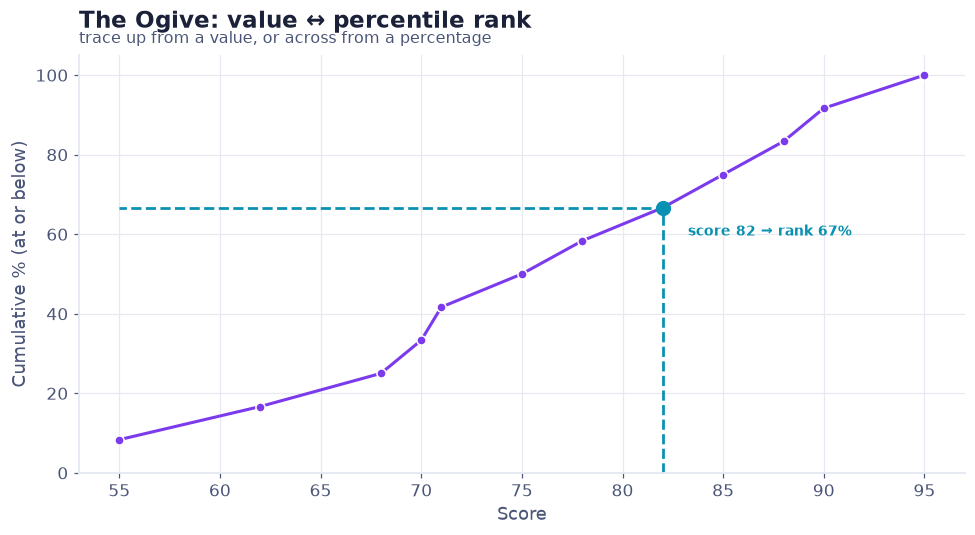

In [4]:
xs = np.sort(scores.values)
cum = np.arange(1, len(xs)+1) / len(xs) * 100   # cumulative percent at or below

fig, ax = plt.subplots(figsize=(9,5))
ax.plot(xs, cum, "-o", color=PURPLE, lw=2, markersize=6, markeredgecolor="white")
# value 82 -> its rank
r = (scores <= 82).mean()*100
ax.plot([82,82,55],[0,r,r], color=CYAN, ls="--", lw=1.8)
ax.scatter([82],[r], color=CYAN, s=80, zorder=5)
ax.text(83, r-7, f" score 82 → rank {r:.0f}%", color=CYAN, fontweight="bold", fontsize=9)
titlecard(ax,"The Ogive: value ↔ percentile rank","trace up from a value, or across from a percentage")
ax.set_xlabel("Score"); ax.set_ylabel("Cumulative % (at or below)"); ax.set_ylim(0,105)
plt.tight_layout(); plt.show()

<div style="background:#e3f6ee;border-left:5px solid #059669;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#047857;letter-spacing:1px">DEMO 4 · POSITION IS ROBUST</span>
<div style="font-size:22px;font-weight:800;color:#1a2138;margin-top:4px">🛡️ Outliers barely move a percentile</div>
<div style="color:#4a5578;margin-top:6px">Because percentiles depend only on rank order, not on how extreme a value is, one wild outlier hardly shifts the median or quartiles, while it wrecks the mean.</div>
</div>

Original : mean   28.6, median 28.0, Q3 32.5
+ outlier: mean  480.5, median 29.0, Q3 34.0

The mean exploded; the median and Q3 barely moved. Position measures are robust.


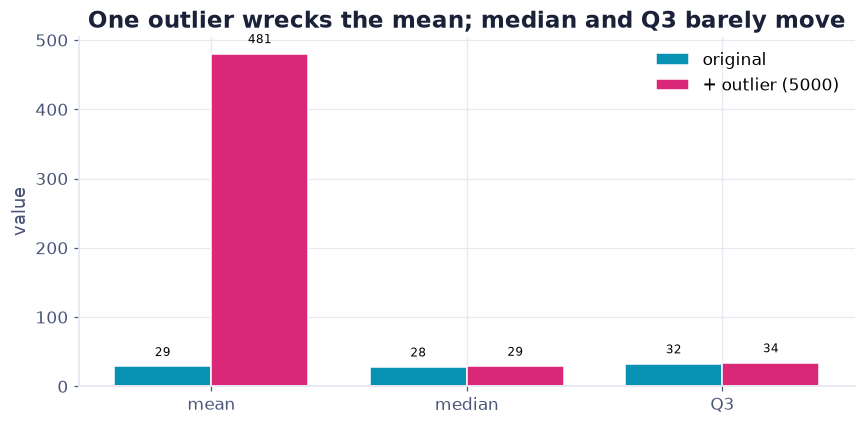

In [5]:
base = pd.Series([20, 22, 24, 25, 27, 29, 31, 33, 35, 40])
withbig = pd.concat([base, pd.Series([5000])], ignore_index=True)

print(f"Original : mean {base.mean():6.1f}, median {base.median():.1f}, Q3 {np.percentile(base,75):.1f}")
print(f"+ outlier: mean {withbig.mean():6.1f}, median {withbig.median():.1f}, Q3 {np.percentile(withbig,75):.1f}")
print("\nThe mean exploded; the median and Q3 barely moved. Position measures are robust.")

# --- added visual ---
import matplotlib.pyplot as plt, numpy as np
_CY,_PU,_AM,_GR,_PK,_INK,_GRY,_BL = "#0891b2","#7c3aed","#d97706","#059669","#db2777","#1a2138","#c7ccda","#2563eb"
labels = ["mean","median","Q3"]
orig = [base.mean(), base.median(), np.percentile(base,75)]
big  = [withbig.mean(), withbig.median(), np.percentile(withbig,75)]
xp = np.arange(3); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(xp-w/2, orig, w, label="original", color=_CY, edgecolor="white")
ax.bar(xp+w/2, big,  w, label="+ outlier (5000)", color=_PK, edgecolor="white")
ax.set_xticks(xp); ax.set_xticklabels(labels); ax.set_ylabel("value"); ax.legend()
ax.set_title("One outlier wrecks the mean; median and Q3 barely move")
for i,(a,b) in enumerate(zip(orig,big)):
    ax.text(i-w/2, a+15, f"{a:.0f}", ha="center", fontsize=8)
    ax.text(i+w/2, b+15, f"{b:.0f}", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

<div style="background:#e6effe;border-left:5px solid #2563eb;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#1d4ed8;letter-spacing:1px">DEMO 5 · WHY ANSWERS DIFFER</span>
<div style="font-size:22px;font-weight:800;color:#1a2138;margin-top:4px">🔧 There is no single "right" percentile</div>
<div style="color:#4a5578;margin-top:6px">For small samples, percentiles fall between data points, so software interpolates differently. NumPy alone offers many methods. Report which you used.</div>
</div>

In [6]:
sample = np.array([2, 4, 6, 8, 10, 12, 14])
print("First quartile (25th percentile) of", list(sample), "by method:")
for m in ["lower", "higher", "nearest", "midpoint", "linear"]:
    print(f"   method={m:<8} -> {np.percentile(sample, 25, method=m):.2f}")
print("\nAll are legitimate. They differ only because the 25% point sits between two values.")

First quartile (25th percentile) of [np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10), np.int64(12), np.int64(14)] by method:
   method=lower    -> 4.00
   method=higher   -> 6.00
   method=nearest  -> 6.00
   method=midpoint -> 5.00
   method=linear   -> 5.00

All are legitimate. They differ only because the 25% point sits between two values.


## 📝 Real-World Example: Exam Scores and Percentile Ranks
A raw score means little until you locate it. Here are 400 final-exam scores: we find the quartiles and the IQR, then take a single score of 85 and report exactly where it sits, its **percentile rank** (what fraction scored at or below it) and its **z-score** (how many standard deviations above the mean).

Q1 = 55.8   median = 65.3   Q3 = 74.4   IQR = 18.7
a score of 85: percentile rank = 92.5%   |   z-score = +1.39


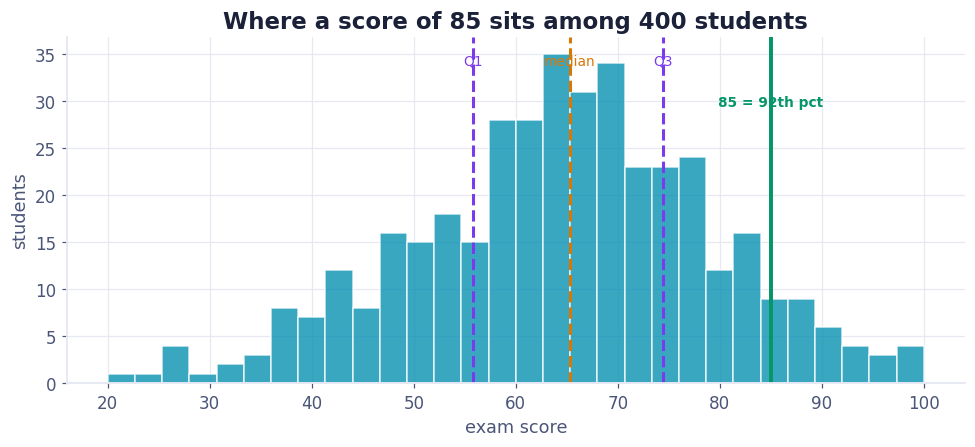

In [7]:
# --- Real-World beat: locate a score with percentile rank and z-score ---
BASE = "https://raw.githubusercontent.com/johnfisher-ai/Statistics-Data-Science-AI-Visual-Book/main/data/"
try:    exam = pd.read_excel("../../data/measures-of-position--exam_scores.xlsx", sheet_name="Data")
except FileNotFoundError: exam = pd.read_excel(BASE+"measures-of-position--exam_scores.xlsx", sheet_name="Data")
q1, med, q3 = exam.exam_score.quantile([.25, .5, .75])
print(f"Q1 = {q1:.1f}   median = {med:.1f}   Q3 = {q3:.1f}   IQR = {q3-q1:.1f}")
val = 85
pct = (exam.exam_score <= val).mean() * 100   # at or below, as the chapter defines it
z = (val - exam.exam_score.mean()) / exam.exam_score.std()
print(f"a score of {val}: percentile rank = {pct:.1f}%   |   z-score = {z:+.2f}")
fig, ax = plt.subplots(figsize=(9,4.2))
ax.hist(exam.exam_score, bins=30, color=CYAN, alpha=0.8, edgecolor="white")
for q, lab, col in [(q1,"Q1",PURPLE), (med,"median",AMBER), (q3,"Q3",PURPLE)]:
    ax.axvline(q, color=col, ls="--", lw=2); ax.text(q, ax.get_ylim()[1]*0.92, lab, ha="center", fontsize=9, color=col)
ax.axvline(val, color=GREEN, lw=2.6); ax.text(val, ax.get_ylim()[1]*0.80, f"{val} = {pct:.0f}th pct", ha="center", fontsize=9, color=GREEN, fontweight="bold")
ax.set_title("Where a score of 85 sits among 400 students")
ax.set_xlabel("exam score"); ax.set_ylabel("students")
plt.tight_layout(); plt.show()

---
<div style="background:#ffffff;border:1px solid #e6e9f2;border-radius:16px;padding:24px 28px;font-family:Inter,sans-serif;box-shadow:0 8px 30px rgba(20,30,80,0.05)">
<div style="font-size:20px;font-weight:800;color:#1a2138">🎓 Recap</div>
<ul style="color:#4a5578;line-height:1.9;margin-top:10px">
<li>A <b>percentile</b> is a value at a position; a <b>percentile rank</b> is the percent at or below a value. Inverse operations.</li>
<li><b>Quartiles, deciles, percentiles</b> are all quantiles: the same idea at different resolutions.</li>
<li>The <b>cumulative S-curve (ogive)</b> shows both directions in one picture.</li>
<li>Position measures are <b>robust</b>: outliers barely move them.</li>
<li>Percentile <b>calculation methods differ</b> on small samples, so report your method.</li>
</ul>
</div>

<div style="text-align:center;color:#8b94b3;font-size:12px;margin-top:18px">Statistics, Data Science and AI: A Visual Handbook · © 2026 John Fisher</div>